In [1]:
import pandas as pd
import sys
from pathlib import Path

ROOT = Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT)) 
from src.data import *


### 1.Разметка сессий и анализ исходов

Разделение Журнала событий на сессии и определение исхода каждой сессии.

**Что делается:**
- Загружается датасет и вызывается функция `mark_sessions()`, которая:
  - Размечает сессии по событиям `Kernel-General:12` (старт)
  - Определяет исход: `FAIL` (если в начале следующей сессии есть `Kernel-Power:41`) или `CENSORED` (штатное завершение или продолжающаяся сессия)
  
- статистика:
  - Общее число событий `Kernel-Power:41` и сколько из них отнесено к предыдущей сессии
  - Общее число сессий и распределение по исходам (FAIL/CENSORED)
  - Сводная таблица по машинам: сколько сессий с каждым исходом
  - таблица: связь исхода с наличием штатной остановки (`has_clean_stop`) и последней сессии (`is_last`)
  - Статистика длительности сессий в часах для FAIL и CENSORED
  - Число сессий нулевой длины


In [2]:
df, sessions = mark_sessions(load_dataset())

print("Kernel-Power:41 всего:", (df["pair"] == K41).sum(),
      "| отнесено к предыдущей сессии:", df["marks_prev_fail"].sum())
print("Сессий всего:", len(sessions))
print(sessions["outcome"].value_counts())
print(sessions.pivot_table(index="machine_id", columns="outcome", values="session_no",
                           aggfunc="count", fill_value=0))
print(pd.crosstab(sessions["outcome"], [sessions["has_clean_stop"], sessions["is_last"]]))

hours = (sessions["t_end"] - sessions["t_start"]).dt.total_seconds() / 3600
print(hours.groupby(sessions["outcome"]).describe().round(2))
print("Сессий нулевой длины:", (hours == 0).sum())

Kernel-Power:41 всего: 300 | отнесено к предыдущей сессии: 294
Сессий всего: 955
outcome
CENSORED    661
FAIL        294
Name: count, dtype: int64
outcome     CENSORED  FAIL
machine_id                
pc_01              8    94
pc_02             46     1
pc_03             66     1
pc_04             58     0
pc_05             58     0
pc_06             73     4
pc_07            209     3
pc_08             24   103
pc_09              9     0
pc_10              1     4
pc_11              1     0
pc_12             12     0
pc_13             40    37
pc_14             23     1
pc_15             17    32
pc_16             16    14
has_clean_stop False       True 
is_last        False True  False
outcome                         
CENSORED           0    16   645
FAIL             294     0     0
          count    mean     std  min   25%    50%    75%      max
outcome                                                          
CENSORED  661.0   43.77  356.19  0.0  0.04   0.48  10.02  5829.56
FAIL

### 2. Журналы компонент (Kernel-Power)
Строится журнал событий для компоненты `Kernel-Power`.

**Что делается:**
- сводка по машинам (`summarize_component_log`):
  - `sessions_all` — всего сессий у машины
  - `sessions_in_log` — сессий с событиями компоненты
  - `events` — число событий компоненты
  - `fail` — число отказов в журнале
  - `share_empty` — доля пустых сессий (убраны из журнала)
  - `events_per_session` — среднее число событий на сессию
- Выводится распределение событий (топ-10 по частоте)
- Журнал сохраняется в `data/processed/component_logs/kernel_power.csv`

переход от общего журнала к журналу конкретной компоненты.

Машины pc_10, pc_11 без событий компоненты, не учитываем их далее

In [3]:
KP = "Microsoft-Windows-Kernel-Power"
kp_log = build_component_log(df, sessions, KP, drop_pairs=(K41,))
print(summarize_component_log(kp_log, sessions))

ev = kp_log[~kp_log["activity"].str.startswith("END_")]
print(ev["activity"].value_counts(normalize=True).head(10).round(3))
print(save_component_log(kp_log, "kernel_power").relative_to(ROOT))

            sessions_all  sessions_in_log  events  fail  share_empty  \
machine_id                                                             
pc_01                102              102     376    94          0.0   
pc_02                 47               47      92     1          0.0   
pc_03                 67               67     132     1          0.0   
pc_04                 58               58     115     0          0.0   
pc_05                 58               58     115     0          0.0   
pc_06                 77               77     149     4          0.0   
pc_07                212              212     629     3          0.0   
pc_08                127              127     800   103          0.0   
pc_09                  9                9     615     0          0.0   
pc_10                  5                0       0     0          1.0   
pc_11                  1                0       0     0          1.0   
pc_12                 12               12     228     0         

### 3. Таблица переходов и анализ вероятностей

строим таблицу переходов между состояниями компоненты и с анализом вероятности перехода одного состояния в другое.

**Что делается:**
- Вызывается `transition_table()`, которая для каждой сессии строит цепочку `START → события → END_*`
- Выводится:
  - Общее число уникальных переходов
  - Топ-10 переходов по количеству (`count`) — какие переходы встречаются чаще всего
  - Топ-10 переходов по вероятности (`prob`), где `count >= 10` — какие переходы почти детерминированы
  - Переходы в конечные состояния (`END_CENSORED`, `END_FAIL`) — из каких состояний чаще происходит завершение


In [4]:
from src.data import load_dataset, mark_sessions, build_component_log
from src.models import transition_table

df, sessions = mark_sessions(load_dataset())

KP = "Microsoft-Windows-Kernel-Power"
K41 = "Microsoft-Windows-Kernel-Power:41"
kp_log = build_component_log(df, sessions, KP, drop_pairs=(K41,))

tt_all = transition_table(kp_log)

print(f"Всего уникальных переходов: {len(tt_all)}")

print("\nТоп-10 переходов по количеству (count):")
print(tt_all.nlargest(10, "count").to_string(index=False))

print("\nТоп-10 переходов по вероятности (prob), где count >= 10:")

tt_significant = tt_all[tt_all["count"] >= 10]
print(tt_significant.nlargest(10, "prob").to_string(index=False))

print("\nПереходы в конечные состояния (END_CENSORED / END_FAIL):")
end_transitions = tt_all[tt_all["dst"].str.startswith("END_")]
print(end_transitions.sort_values("count", ascending=False).head(10).to_string(index=False))

Всего уникальных переходов: 91

Топ-10 переходов по количеству (count):
src dst  count     prob
566 506   5011 0.431574
507 566   4959 0.999597
506 566   3467 0.691878
566 566   2237 0.192662
566 507   2069 0.178193
506 507   1366 0.272600
 42 107   1084 1.000000
566 172   1036 0.089226
172 507    972 0.326613
566 105    862 0.074240

Топ-10 переходов по вероятности (prob), где count >= 10:
  src          dst  count     prob
   42          107   1084 1.000000
  577 END_CENSORED     95 1.000000
  507          566   4959 0.999597
  131          130    369 0.960938
  130           42    329 0.891599
  109 END_CENSORED    550 0.852713
START          172    797 0.839831
  578          521     25 0.781250
  506          566   3467 0.691878
  187           42    320 0.645161

Переходы в конечные состояния (END_CENSORED / END_FAIL):
src          dst  count     prob
109 END_CENSORED    550 0.852713
107     END_FAIL    134 0.123616
577 END_CENSORED     95 1.000000
172     END_FAIL     77 0.02587

### 4. Сохранение схем по машинам и построение сетей Петри

Сохраняем таблицы переходов для каждой машины в JSON и строим сети Петри.

машины с малым числом сессий/событий исключаются


In [5]:
import os
os.environ["PATH"] += os.pathsep + r"C:\Program Files\Graphviz\bin"
from src.models import *

COMPONENT = "kernel_power"

print("Сохранение JSON-схем переходов по машинам ===")
schemes_dir = save_machine_schemes(kp_log, COMPONENT)
print(f"Схемы сохранены в: {schemes_dir}")

print(" 2. Построение и сохранение сетей Петри ")
# Пороги: 20 сессий и 50 событий
petri_dir, valid_m, excluded_m = save_machine_petri_nets(
    kp_log, COMPONENT, min_sessions=20, min_events=50
)
print(f"Картинки сетей Петри сохранены в: {petri_dir}")

Сохранение JSON-схем переходов по машинам ===
Схемы сохранены в: C:\Users\lena\Desktop\diplom\EquipmentEventLogGeneration\results\schemes\kernel_power
 2. Построение и сохранение сетей Петри 
Всего машин в логе: 14
Будет построено сетей Петри: 12 (сессий >= 20, событий >= 50)
 Исключены (мало данных): ['pc_09', 'pc_12']
Картинки сетей Петри сохранены в: C:\Users\lena\Desktop\diplom\EquipmentEventLogGeneration\results\petri_nets\kernel_power


Машина 2

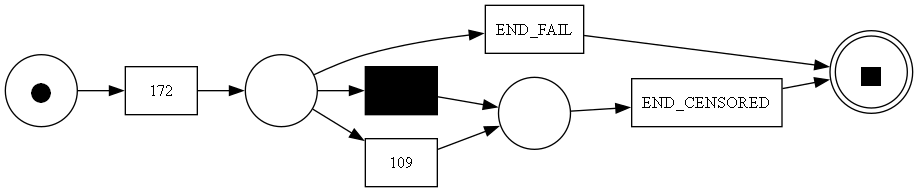


Машина 5

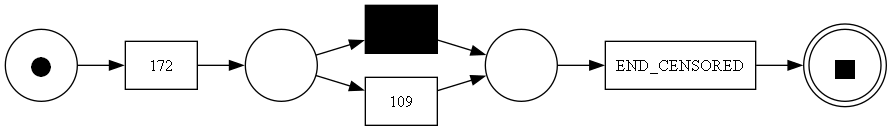

Машина 8

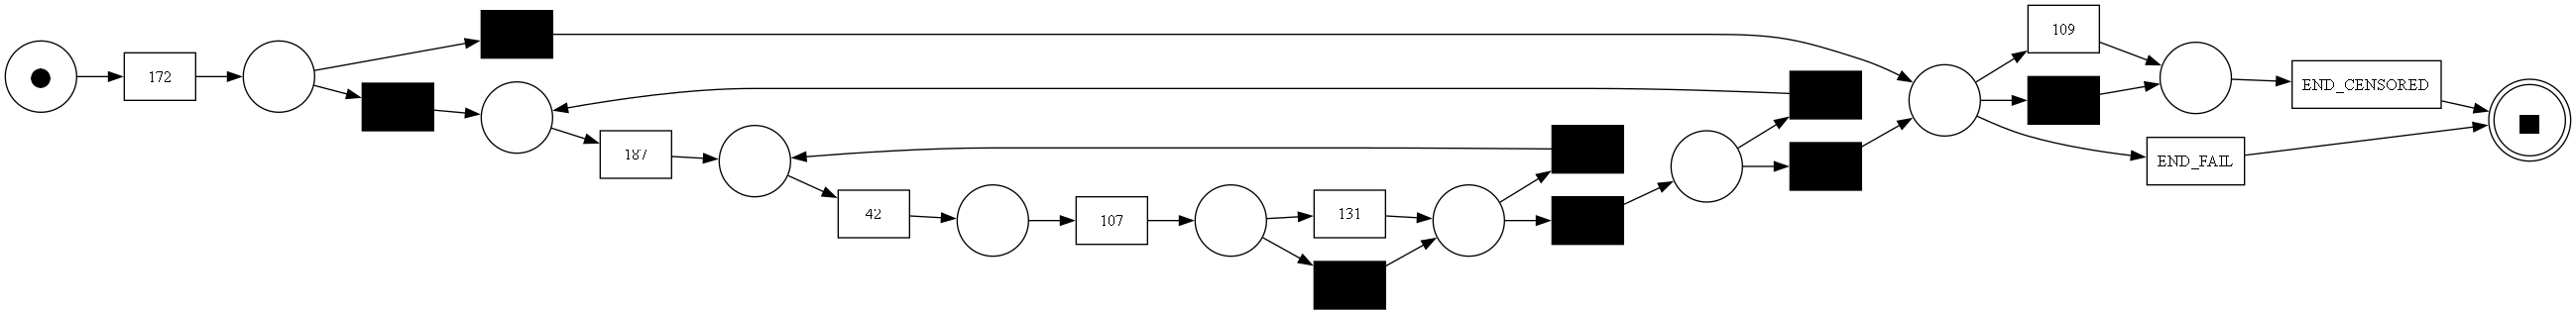

Машина 16

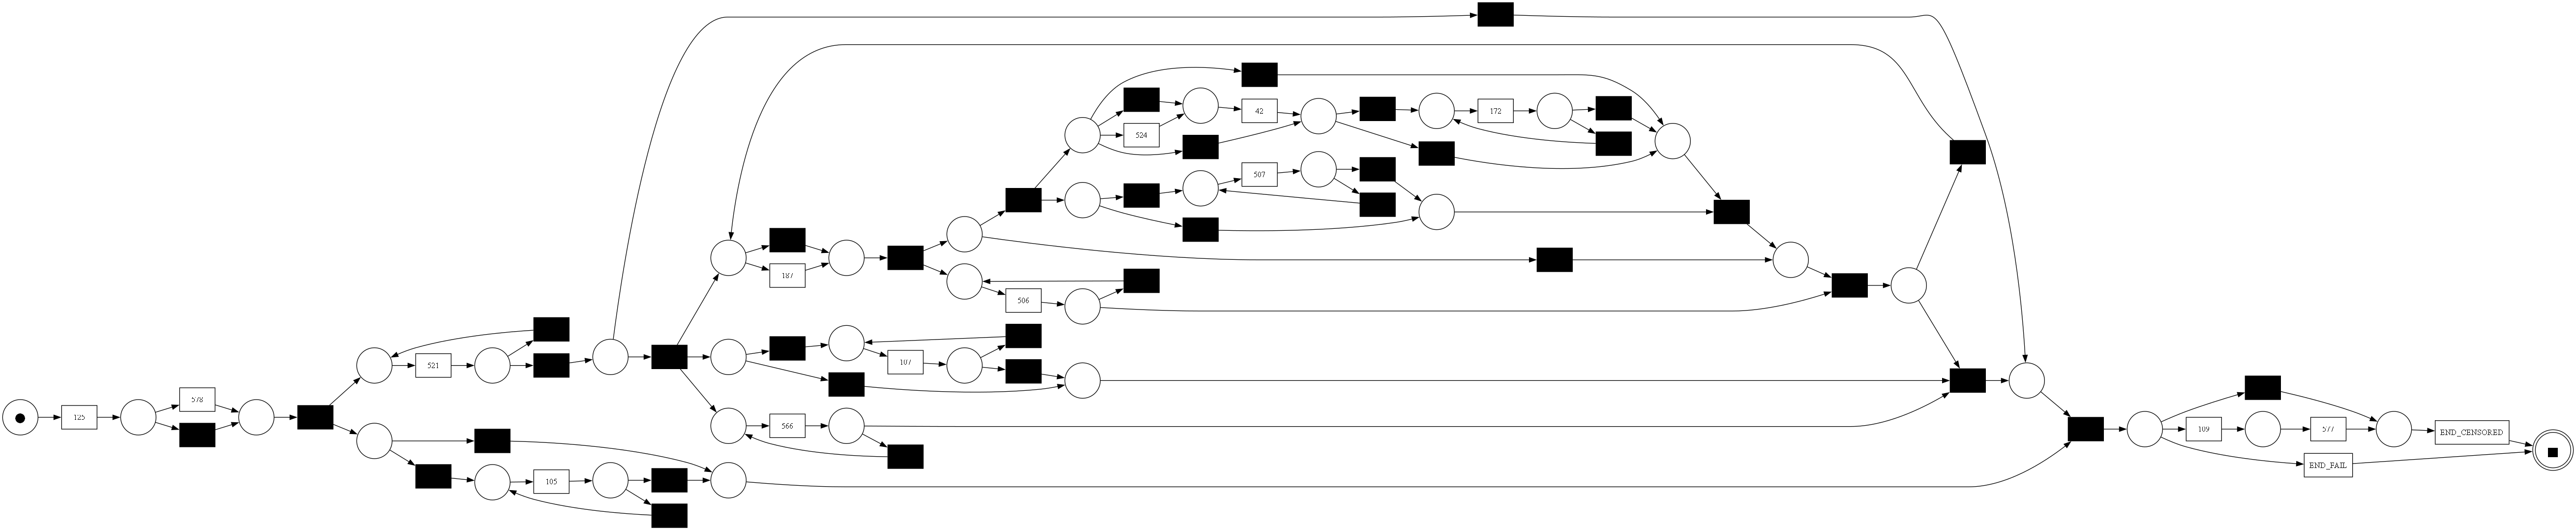